## RUN THIS AT THE BEGINNING

### imports & path stuff

In [2]:
from pathlib import Path
import sys
# import os4
from typing import Union
import os

def from_root(relative_path: Union[str, Path]) -> Path:
    return REPO_ROOT / Path(relative_path)

def _ensure_repo_root_on_path(start: Path) -> Path:
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "src").exists():
            repo_root = str(candidate)
            if repo_root not in sys.path:
                sys.path.insert(0, repo_root)
            return candidate
    raise RuntimeError("Could not locate project root containing 'src'")

REPO_ROOT = _ensure_repo_root_on_path(Path.cwd())
os.chdir(REPO_ROOT)

# def from_root(relative_path: str | Path) -> Path:
#     return REPO_ROOT / Path(relative_path)

print(f"repo root on sys.path: {REPO_ROOT}")
print(f"cwd set to: {Path.cwd()}")

repo root on sys.path: /home/kostouso/CompNeuro/Computational_Neuroscience_-25--26
cwd set to: /home/kostouso/CompNeuro/Computational_Neuroscience_-25--26


In [3]:
from torchvision.datasets import CIFAR10
from torch.utils.data import DataLoader
from torch import nn
import torch
from src.models.simclr_model import downsizedSimCLR, SimCLR
from src.utils.model_activations import ModelActivations
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from src.latest_neural_data.ev_helper import forward_ev, reverse_ev
from src.latest_neural_data.model_acts import extract_model_activations_from_cache
from src.eval.linear_probe import linear_probe_standalone, linear_probe_adversarial_robustness_standalone
import pandas as pd
from src.losses.spectral_loss import just_alpha_imgnet_standalone, just_alpha_brainscore_standalone
from src.utils.post_training import extract_stats, extract_ckpt_args, extract_model_weights, to_flt
from src.utils.post_training import *
import matplotlib.colors as mcolors

In [ ]:
neural_data = torch.load("src/metrics/neural_data/averaged_neural_data.pt")

In [ ]:
stimulus_categories = torch.load("src/metrics/neural_data/stimulus_categories.pt")

In [5]:
len(stimulus_categories)

3200

In [6]:
stimulus_categories[:20]

['Cars',
 'Tables',
 'Faces',
 'Fruits',
 'Fruits',
 'Planes',
 'Fruits',
 'Fruits',
 'Faces',
 'Planes',
 'Boats',
 'Boats',
 'Cars',
 'Animals',
 'Fruits',
 'Cars',
 'Tables',
 'Cars',
 'Planes',
 'Boats']

In [7]:
neural_data.shape

torch.Size([3200, 168])

In [8]:
neural_data.min(), neural_data.max()

(tensor(-1.9345), tensor(4.1266))

In [4]:
from src.utils.construct_df import construct_df
df = construct_df()

retrieving trial 650/650

### main analysis

In [ ]:
df_filtered = df[((df["version"]=="fixed alpha_loss_04042026") & (df["epochs"]>=199) & (df["recomputed_alpha"]<=1.6) & (df["tau"]==0.2)) | ((df["spectral_loss_coeff"]==0)& (df["tau"]==0.2))]

print(len(df_filtered))

alpha = to_flt(df_filtered["recomputed_alpha"])
tgt_alpha = to_flt(df_filtered["target_alpha"])

print(df_filtered["recomputed_alpha"].unique())
f_ev = to_flt(df_filtered["recomputed_F_EV"])
r_ev = to_flt(df_filtered["recomputed_R_EV"])
spectral_loss_coeff = to_flt(df_filtered["spectral_loss_coeff"])
ed = to_flt(df_filtered["recomputed_brainscore_ed"])
common_f = to_flt(df_filtered["recomputed_common_F_EV"])
common_r = to_flt(df_filtered["recomputed_common_R_EV"])
unique_f = to_flt(df_filtered["recomputed_unique_F_EV"])
unique_r = to_flt(df_filtered["recomputed_unique_R_EV"])

print("Correlation:", np.corrcoef(f_ev, spectral_loss_coeff)[0, 1])

print("Correlation:", np.corrcoef(r_ev, alpha)[0, 1])

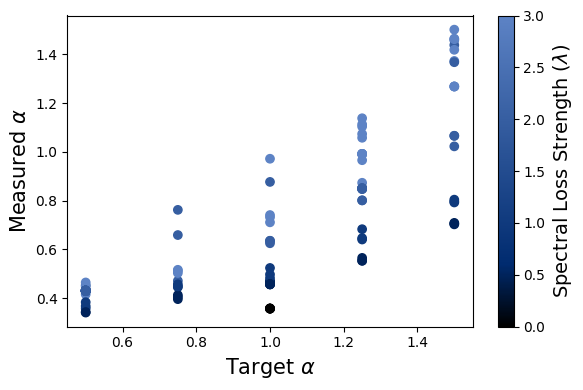

In [86]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable

cmap = LinearSegmentedColormap.from_list(
    "black_darkblue_warmblue",
    [
        (0.0, "#000000"),
        (0.2, "#002b6f"),
        (1.0, "#5d83c5"),
    ]
)

norm = Normalize(
    vmin=df_filtered["spectral_loss_coeff"].min(),
    vmax=df_filtered["spectral_loss_coeff"].max(),
)

fig, ax = plt.subplots(figsize=(6, 4))

scatter = ax.scatter(
    df_filtered["target_alpha"],
    df_filtered["recomputed_alpha"],
    c=df_filtered["spectral_loss_coeff"],
    cmap=cmap,
    norm=norm,
    marker="o",
)

ax.set_xlabel(r"Target $\alpha$", fontsize=15)
ax.set_ylabel(r"Measured $\alpha$", fontsize=15)

cbar = fig.colorbar(scatter, ax=ax)
cbar.set_label(r"Spectral Loss Strength ($\lambda$)", fontsize=14)

plt.tight_layout()
plt.show()

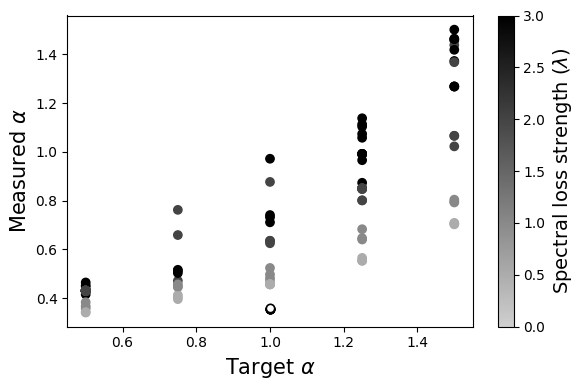

In [87]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list(
    "grayscale_scheme_reversed",
    [
        (0.0, "#cfcfcf"),  # light gray at minimum
        (0.5, "#666666"),  # medium gray
        (1.0, "#000000"),  # black at maximum
    ]
)

coeff = df_filtered["spectral_loss_coeff"]

norm = Normalize(
    vmin=coeff.min(),
    vmax=coeff.max(),
)

fig, ax = plt.subplots(figsize=(6, 4))

# Non-baseline points
nonzero_mask = coeff != 0

scatter = ax.scatter(
    df_filtered.loc[nonzero_mask, "target_alpha"],
    df_filtered.loc[nonzero_mask, "recomputed_alpha"],
    c=coeff.loc[nonzero_mask],
    cmap=cmap,
    norm=norm,
    marker="o",
    zorder=2,
)

# Baseline points: hollow circles, matching the other plot
zero_mask = coeff == 0

ax.scatter(
    df_filtered.loc[zero_mask, "target_alpha"],
    df_filtered.loc[zero_mask, "recomputed_alpha"],
    facecolors="white",
    edgecolors="black",
    linewidths=1.2,
    marker="o",
    label=r"Baseline ($\lambda=0$)",
    zorder=3,
)

ax.set_xlabel(r"Target $\alpha$", fontsize=15)
ax.set_ylabel(r"Measured $\alpha$", fontsize=15)

cbar = fig.colorbar(scatter, ax=ax)
cbar.set_label(
    r"Spectral loss strength ($\lambda$)",
    fontsize=14,
)

plt.tight_layout()
plt.show()

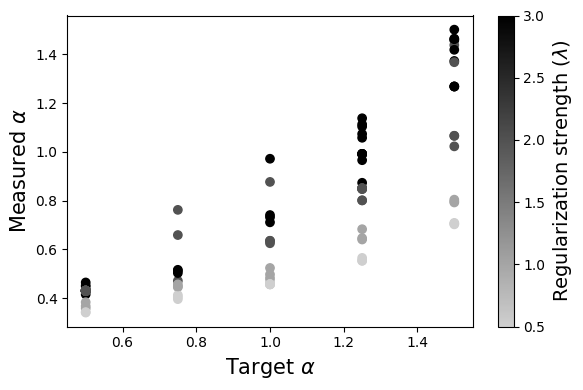

In [88]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LinearSegmentedColormap

plot_df = df_filtered[df_filtered["spectral_loss_coeff"] != 0].copy()

cmap = LinearSegmentedColormap.from_list(
    "grayscale_scheme_reversed",
    [
        (0.0, "#cfcfcf"),
        (0.5, "#666666"),
        (1.0, "#000000"),
    ]
)

norm = Normalize(
    vmin=plot_df["spectral_loss_coeff"].min(),
    vmax=plot_df["spectral_loss_coeff"].max(),
)

fig, ax = plt.subplots(figsize=(6, 4))

scatter = ax.scatter(
    plot_df["target_alpha"],
    plot_df["recomputed_alpha"],
    c=plot_df["spectral_loss_coeff"],
    cmap=cmap,
    norm=norm,
    marker="o",
)

ax.set_xlabel(r"Target $\alpha$", fontsize=15)
ax.set_ylabel(r"Measured $\alpha$", fontsize=15)

cbar = fig.colorbar(scatter, ax=ax)
cbar.set_label(
    r"Regularization strength ($\lambda$)",
    fontsize=14,
)
# plt.ylim(0.2, 1.6)
# plt.xlim(0.2, 1.6)

plt.tight_layout()
plt.savefig("target_vs_measured_alpha.png", dpi=600, bbox_inches="tight")
plt.show()

In [29]:
df_filtered = df[((df["version"]=="fixed alpha_loss_04042026") & (df["epochs"]>=199) & (df["recomputed_alpha"]<=1.6) & (df["target_alpha"]<=2) & (df["tau"]==0.2)) | ((df["spectral_loss_coeff"]==0)& (df["tau"]==0.2))]

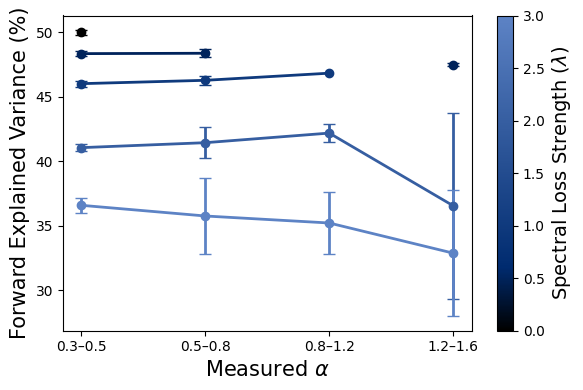

In [30]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap


# alpha_ranges = [(0.2, 0.4), (0.4, 0.8), (0.8, 1.2), (1.2, 1.6)]
alpha_ranges = [(0.2, 0.4), (0.2, 0.4), (0.5, 0.8), (0.8, 1.2), (1.2, 1.6)]

bin_edges = [0.2, 0.5, 0.8, 1.2, 1.6]
bin_labels = ["0.3–0.5", "0.5–0.8", "0.8–1.2", "1.2–1.6"]

plot_df = pd.DataFrame({
    "alpha": alpha,
    "f_ev": f_ev,
    "spectral_loss_coeff": spectral_loss_coeff,
})

plot_df["alpha_bin"] = pd.cut(
    plot_df["alpha"],
    bins=bin_edges,
    labels=bin_labels,
    include_lowest=True,
    right=True,
)

binned = (
    plot_df
    .dropna(subset=["alpha_bin"])
    .groupby(["spectral_loss_coeff", "alpha_bin"], observed=True)["f_ev"]
    .agg(["mean", "std", "count"])
    .reset_index()
)


# cmap = plt.get_cmap("winter_r")
# cmap = LinearSegmentedColormap.from_list(
#     "black_to_warm_blue",
#     [
#         "#000000",  # black
#         "#9bbcff",  # warm soft blue
#     ]
# )


cmap = LinearSegmentedColormap.from_list(
    "black_darkblue_warmblue",
    [
        (0.0, "#000000"),
        (0.2, "#002b6f"),
        (1.0, "#5d83c5"),
    ]
)

coeffs = sorted(binned["spectral_loss_coeff"].dropna().unique())
norm = Normalize(vmin=min(coeffs), vmax=max(coeffs))

fig, ax = plt.subplots(figsize=(6, 4))

x = range(len(bin_labels))

for coeff, g in binned.groupby("spectral_loss_coeff"):
    g = g.set_index("alpha_bin").reindex(bin_labels)
    ax.errorbar(
        x,
        g["mean"],
        yerr=g["std"],
        marker="o",
        linewidth=2,
        capsize=4,
        color=cmap(norm(coeff)),
        label=f"{coeff:g}",
    )

ax.set_xticks(x)
ax.set_xticklabels(bin_labels)
ax.set_xlabel(r"Measured $\alpha$", fontsize=15)
ax.set_ylabel("Forward Explained Variance (%)", fontsize=15)

# Colorbar instead of legend
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label(r"Spectral Loss Strength ($\lambda$)", fontsize=14)

plt.tight_layout()
plt.savefig("flambda.png", dpi=600, bbox_inches="tight")
plt.show()


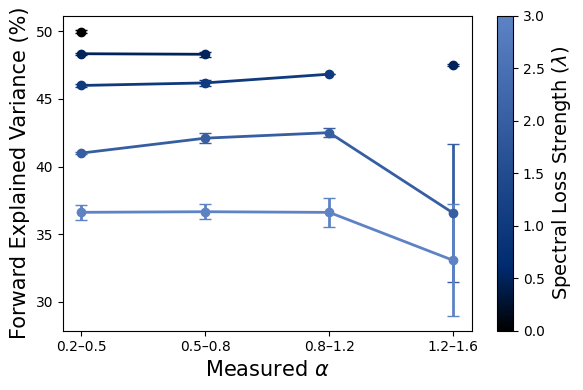

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap


def mad(x):
    """
    Median absolute deviation.

    Raw MAD:
        median(|x - median(x)|)

    If you want it on roughly the same scale as std under a normal
    distribution, return 1.4826 * mad instead.
    """
    x = np.asarray(x.dropna())
    med = np.median(x)
    return np.median(np.abs(x - med))


bin_edges = [0.2, 0.5, 0.8, 1.2, 1.6]
bin_labels = ["0.2–0.5", "0.5–0.8", "0.8–1.2", "1.2–1.6"]

plot_df = pd.DataFrame({
    "alpha": alpha,
    "f_ev": f_ev,
    "spectral_loss_coeff": spectral_loss_coeff,
})

plot_df["alpha_bin"] = pd.cut(
    plot_df["alpha"],
    bins=bin_edges,
    labels=bin_labels,
    include_lowest=True,
    right=True,
)

binned = (
    plot_df
    .dropna(subset=["alpha_bin"])
    .groupby(["spectral_loss_coeff", "alpha_bin"], observed=True)["f_ev"]
    .agg(
        median="median",
        mad=mad,
        count="count",
    )
    .reset_index()
)

cmap = LinearSegmentedColormap.from_list(
    "black_darkblue_warmblue",
    [
        (0.0, "#000000"),
        (0.2, "#002b6f"),
        (1.0, "#5d83c5"),
    ]
)

coeffs = sorted(binned["spectral_loss_coeff"].dropna().unique())
norm = Normalize(vmin=min(coeffs), vmax=max(coeffs))

fig, ax = plt.subplots(figsize=(6, 4))

x = range(len(bin_labels))

for coeff, g in binned.groupby("spectral_loss_coeff"):
    g = g.set_index("alpha_bin").reindex(bin_labels)

    ax.errorbar(
        x,
        g["median"],
        yerr=g["mad"],
        marker="o",
        linewidth=2,
        capsize=4,
        color=cmap(norm(coeff)),
        label=f"{coeff:g}",
    )

ax.set_xticks(x)
ax.set_xticklabels(bin_labels)
ax.set_xlabel(r"Measured $\alpha$", fontsize=15)
ax.set_ylabel("Forward Explained Variance (%)", fontsize=15)

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label(r"Spectral Loss Strength ($\lambda$)", fontsize=14)

plt.tight_layout()
plt.savefig("flambda.png", dpi=600, bbox_inches="tight")
plt.show()

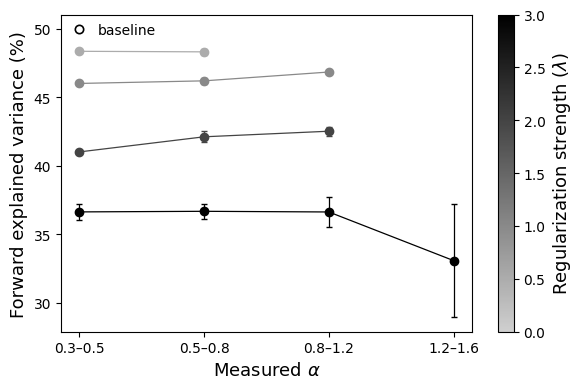

In [32]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap


# alpha_ranges = [(0.2, 0.4), (0.4, 0.8), (0.8, 1.2), (1.2, 1.6)]
alpha_ranges = [(0.2, 0.4), (0.2, 0.5), (0.5, 0.8), (0.8, 1.2), (1.2, 1.6)]

bin_edges = [0.2, 0.5, 0.8, 1.2, 1.6]
bin_labels = ["0.3–0.5", "0.5–0.8", "0.8–1.2", "1.2–1.6"]

plot_df = pd.DataFrame({
    "alpha": alpha,
    "f_ev": f_ev,
    "spectral_loss_coeff": spectral_loss_coeff,
})

plot_df["alpha_bin"] = pd.cut(
    plot_df["alpha"],
    bins=bin_edges,
    labels=bin_labels,
    include_lowest=True,
    right=True,
)

# binned = (
#     plot_df
#     .dropna(subset=["alpha_bin"])
#     .groupby(["spectral_loss_coeff", "alpha_bin"], observed=True)["f_ev"]
#     .agg(["mean", "std", "count"])
#     .reset_index()
# )


binned = (
    plot_df
    .dropna(subset=["alpha_bin"])
    .groupby(["spectral_loss_coeff", "alpha_bin"], observed=True)["f_ev"]
    .agg(
        median="median",
        mad=mad,
        count="count",
    )
    .reset_index()
)

# cmap = plt.get_cmap("winter_r")
# cmap = LinearSegmentedColormap.from_list(
#     "black_to_warm_blue",
#     [
#         "#000000",  # black
#         "#9bbcff",  # warm soft blue
#     ]
# )


cmap = LinearSegmentedColormap.from_list(
    "grayscale_scheme_reversed",
    [
        (0.0, "#cfcfcf"),  # light gray at min
        (0.5, "#666666"),  # medium gray
        (1.0, "#000000"),  # black at max
    ]
)

coeffs = sorted(binned["spectral_loss_coeff"].dropna().unique())
norm = Normalize(vmin=min(coeffs), vmax=max(coeffs))

fig, ax = plt.subplots(figsize=(6, 4))

x = range(len(bin_labels))

for coeff, g in binned.groupby("spectral_loss_coeff"):
    g = g.set_index("alpha_bin").reindex(bin_labels)

    if coeff == 0:
        ax.plot(
            x,
            g["median"],
            marker="o",
            linewidth=2,
            color="black",
            markerfacecolor="white",
            markeredgecolor="black",
            markeredgewidth=1.2,
            label=f"{coeff:g}",
        )
    elif coeff == 2:
        ax.errorbar(
            x[:-1],
            g["median"][:-1],
            yerr=g["mad"][:-1],
            marker="o",
            linewidth=0.9,
            capsize=2,
            color=cmap(norm(coeff)),
            label=f"{coeff:g}",
            zorder=3,
        )
    elif coeff ==0.5:
        ax.errorbar(
            x[:-1],
            g["median"][:-1],
            yerr=g["mad"][:-1],
            marker="o",
            linewidth=0.9,
            capsize=2,
            color=cmap(norm(coeff)),
            label=f"{coeff:g}",
            zorder=3,
        )
    else:
        ax.errorbar(
            x,
            g["median"],
            yerr=g["mad"],
            marker="o",
            linewidth=0.9,
            capsize=2,
            color=cmap(norm(coeff)),
            label=f"{coeff:g}",
        )

ax.set_xticks(x)
ax.set_xticklabels(bin_labels)
ax.set_xlabel(r"Measured $\alpha$", fontsize=13)
ax.set_ylabel("Forward explained variance (%)", fontsize=13)

ax.text(
    0.23,
    0.974,
    r"baseline",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10
)

# Colorbar instead of legend
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label(r"Regularization strength ($\lambda$)", fontsize=13)

plt.tight_layout()
plt.savefig("flambda.png", dpi=600, bbox_inches="tight")
plt.show()

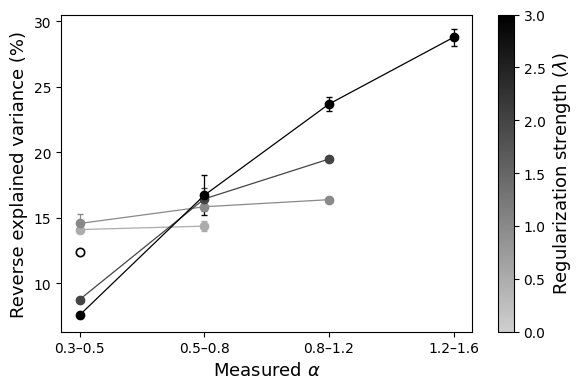

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap


# alpha_ranges = [(0.2, 0.4), (0.4, 0.8), (0.8, 1.2), (1.2, 1.6)]
alpha_ranges = [(0.2, 0.4), (0.2, 0.5), (0.5, 0.8), (0.8, 1.2), (1.2, 1.6)]

bin_edges = [0.2, 0.5, 0.8, 1.2, 1.6]
bin_labels = ["0.3–0.5", "0.5–0.8", "0.8–1.2", "1.2–1.6"]

plot_df = pd.DataFrame({
    "alpha": alpha,
    "r_ev": r_ev,
    "spectral_loss_coeff": spectral_loss_coeff,
})

plot_df["alpha_bin"] = pd.cut(
    plot_df["alpha"],
    bins=bin_edges,
    labels=bin_labels,
    include_lowest=True,
    right=True,
)

# binned = (
#     plot_df
#     .dropna(subset=["alpha_bin"])
#     .groupby(["spectral_loss_coeff", "alpha_bin"], observed=True)["r_ev"]
#     .agg(["mean", "std", "count"])
#     .reset_index()
# )

binned = (
    plot_df
    .dropna(subset=["alpha_bin"])
    .groupby(["spectral_loss_coeff", "alpha_bin"], observed=True)["r_ev"]
    .agg(
        median="median",
        mad=mad,
        count="count",
    )
    .reset_index()
)


cmap = LinearSegmentedColormap.from_list(
    "grayscale_scheme_reversed",
    [
        (0.0, "#cfcfcf"),  # light gray at min
        (0.5, "#666666"),  # medium gray
        (1.0, "#000000"),  # black at max
    ]
)

coeffs = sorted(binned["spectral_loss_coeff"].dropna().unique())
norm = Normalize(vmin=min(coeffs), vmax=max(coeffs))

fig, ax = plt.subplots(figsize=(6, 4))

x = range(len(bin_labels))

for coeff, g in binned.groupby("spectral_loss_coeff"):
    g = g.set_index("alpha_bin").reindex(bin_labels)

    if coeff == 0:
        ax.plot(
            x,
            g["median"],
            marker="o",
            linewidth=2,
            color="black",
            markerfacecolor="white",
            markeredgecolor="black",
            markeredgewidth=1.2,
            label=f"{coeff:g}",
            zorder=10
        )
    elif coeff == 2 or coeff==0.5:#manually making not visible the datapoints for coeff=2 and coeff=0.5 in the largest alpha bin becuase the means are computed from too few datapoints and the errorbars render the result meaningless
        ax.errorbar(
            x[:-1],
            g["median"][:-1],
            yerr=g["mad"][:-1],
            marker="o",
            linewidth=0.9,
            capsize=2,
            color=cmap(norm(coeff)),
            label=f"{coeff:g}",
            zorder=3,
        )
    else:
        ax.errorbar(
            x,
            g["median"],
            yerr=g["mad"],
            marker="o",
            linewidth=0.9,
            capsize=2,
            color=cmap(norm(coeff)),
            label=f"{coeff:g}",
            zorder=3,
        )

ax.set_xticks(x)
ax.set_xticklabels(bin_labels)
ax.set_xlabel(r"Measured $\alpha$", fontsize=13)
ax.set_ylabel("Reverse explained variance (%)", fontsize=13)

# Colorbar instead of legend
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label(r"Regularization strength ($\lambda$)", fontsize=13)

plt.tight_layout()
plt.savefig("rlambda.png", dpi=600, bbox_inches="tight")
plt.show()

In [38]:
def err(x):
    return np.median(np.abs(x - np.median(x)))

In [ ]:
alpha_ranges = [(0.2, 0.4), (0.2, 0.5), (0.5, 0.8), (0.8, 1.2), (1.2, 1.6)]



spec_loss_lb = 2
spec_loss_ub = 2

colors = ["darkred", "darkblue", "green", "darkgreen"]
dictionary = {}
for (s,e) in alpha_ranges:
    if s==0.2 and e==0.4:
        df_filtered = df[((df["spectral_loss_coeff"]==0) & (df["tau"]==0.2))]
    else:
        df_filtered = df[(df["version"]=="fixed alpha_loss_04042026") & (df["epochs"]>=199) & (df["spectral_loss_coeff"]>=spec_loss_lb)& (df["spectral_loss_coeff"]<=spec_loss_ub) & ((df["recomputed_alpha"]>=s) & (df["recomputed_alpha"]<=e))]

    f_evs= []
    r_evs = []
    eds = []
    alphas = []
    c_fs = []
    c_rs = []
    u_fs = []
    u_rs = []
    spec_2 = 0
    spec_3 = 0
    for idx, row in df_filtered.iterrows():
        f_ev = row["recomputed_F_EV"]
        r_ev = row["recomputed_R_EV"]
        alpha = row["recomputed_alpha"]
        ed= row["recomputed_brainscore_ed"]
        common_f = row["recomputed_common_F_EV"]
        common_r = row["recomputed_common_R_EV"]
        unique_f = row["recomputed_unique_F_EV"]
        unique_r = row["recomputed_unique_R_EV"]
        f_evs.append(f_ev)
        r_evs.append(r_ev)
        alphas.append(alpha)
        eds.append(ed)
        c_fs.append(common_f)
        c_rs.append(common_r)
        u_fs.append(unique_f)
        u_rs.append(unique_r)
        if row["spectral_loss_coeff"]==2:
            spec_2+=1
        elif row["spectral_loss_coeff"] ==3:
            spec_3+=1
    print(rf"s: {s} | e: {e} | n: {len(alphas)} | $\lambda=2$: {spec_2} | $\lambda=3$: {spec_3} |")
    print(r_evs)

    dictionary[f"{s},{e}"] = ((np.nanmedian(f_evs), err(f_evs), np.nanmedian(r_evs), err(r_evs)), (np.nanmedian(alphas), err(alphas)), (s, e), (np.nanmedian(eds), err(eds)), (np.nanmedian(c_fs), err(c_fs), np.nanmedian(c_rs), err(c_rs)), (np.nanmedian(u_fs), err(u_fs), np.nanmedian(u_rs), err(u_rs)), len(alphas))

s: 0.2 | e: 0.4 | n: 5 | $\lambda=2$: 0 | $\lambda=3$: 0 |
[12.39053648518312, 12.352675753017278, 12.343462815479429, 12.39509318417486, 12.366596168314896]
s: 0.2 | e: 0.5 | n: 31 | $\lambda=2$: 31 | $\lambda=3$: 0 |
[8.609625875407463, 13.62156612246786, 10.879399224350903, 8.778112540462889, 8.754460798347509, 8.772606113065477, 8.771890279807478, 8.772136725523321, 8.773029234187947, 8.753553023147118, 8.753406643012827, 8.775791322710685, 8.76915797765129, 8.751597620571502, 8.78925151057534, 8.76622430336144, 8.77378945970768, 8.747254954332902, 8.777591929016532, 8.798329301811332, 8.80285742273901, 8.772145999501209, 8.793587785414772, 8.79376075650622, 8.765492155032742, 8.763454447978447, 8.803038766947356, 8.793278189350858, 8.792218988579908, 8.774099565681318, 8.782985604332262]
s: 0.5 | e: 0.8 | n: 5 | $\lambda=2$: 5 | $\lambda=3$: 0 |
[14.168227624566644, 16.446914379552904, 17.194273343149035, 15.309109169985364, 17.264599332059895]
s: 0.8 | e: 1.2 | n: 13 | $\lambda=2

alpha: 0.36 +/- 0.00 | f_ev: 49.97 +/- 0.13 | r_ev: 12.37 +/- 0.02 | n: 5
alpha: 0.43 +/- 0.00 | f_ev: 41.00 +/- 0.08 | r_ev: 8.77 +/- 0.02 | n: 31
alpha: 0.64 +/- 0.01 | f_ev: 42.10 +/- 0.39 | r_ev: 16.45 +/- 0.82 | n: 5
alpha: 0.85 +/- 0.00 | f_ev: 42.50 +/- 0.33 | r_ev: 19.49 +/- 0.12 | n: 13
alpha: 1.40 +/- 0.04 | f_ev: 36.56 +/- 5.10 | r_ev: 17.99 +/- 4.21 | n: 2
alpha: 0.36 +/- 0.00 | f_ev_c: 50.49 +/- 0.07 | f_ev_u: 20.02 +/- 0.08 | r_ev_c: 24.53 +/- 0.01 | r_ev_u: 3.56 +/- 0.01
alpha: 0.43 +/- 0.00 | f_ev_c: 41.11 +/- 0.10 | f_ev_u: 19.47 +/- 0.05 | r_ev_c: 21.03 +/- 0.03 | r_ev_u: 1.11 +/- 0.00
alpha: 0.64 +/- 0.01 | f_ev_c: 45.87 +/- 0.54 | f_ev_u: 17.51 +/- 0.50 | r_ev_c: 32.12 +/- 0.94 | r_ev_u: 5.14 +/- 0.04
alpha: 0.85 +/- 0.00 | f_ev_c: 46.23 +/- 0.38 | f_ev_u: 18.53 +/- 0.31 | r_ev_c: 35.21 +/- 0.13 | r_ev_u: 6.14 +/- 0.04
alpha: 1.40 +/- 0.04 | f_ev_c: 36.55 +/- 7.43 | f_ev_u: 15.81 +/- 8.47 | r_ev_c: 34.68 +/- 2.48 | r_ev_u: 5.37 +/- 2.91


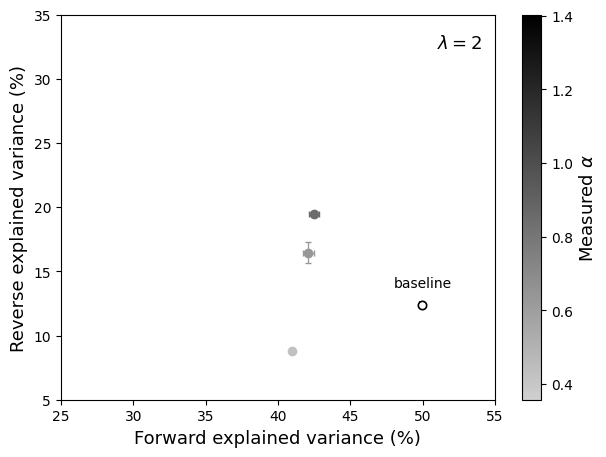

[49.97036595988682, 40.995175344406405, 42.09739367822951, 42.50498949717452, 36.55862047185501]
[0.13329103205928305, 0.07884000267644353, 0.3894719678841341, 0.3294305450780328, 5.10473048142728]
[12.366596168314896, 8.77378945970768, 16.446914379552904, 19.485538156455423, 17.99487078127283]
[0.023133352835467136, 0.015462050867659727, 0.8176849525069905, 0.11743025571891863, 4.2056937432988715]
[0.35738769 0.43066355 0.63550502 0.85054238 1.40252105]
[7.86846280e-05 7.56234217e-04 1.01941427e-02 3.43398142e-03
 3.50949653e-02]


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

f_ev = [value[0][0] for key, value in dictionary.items()]
f_ev_std = [value[0][1] for key, value in dictionary.items()]
r_ev = [value[0][2] for key, value in dictionary.items()]
r_ev_std = [value[0][3] for key, value in dictionary.items()]
alphas = np.array([value[1][0] for key, value in dictionary.items()])
alphas_std = np.array([value[1][1] for key, value in dictionary.items()])

s_e = [value[2] for key, value in dictionary.items()]
c_f = [value[4][0] for key, value in dictionary.items()]
c_f_std = [value[4][1] for key, value in dictionary.items()]
c_r = [value[4][2] for key, value in dictionary.items()]
c_r_std = [value[4][3] for key, value in dictionary.items()]
u_f = [value[5][0] for key, value in dictionary.items()]
u_f_std = [value[5][1] for key, value in dictionary.items()]
u_r = [value[5][2] for key, value in dictionary.items()]
u_r_std = [value[5][3] for key, value in dictionary.items()]
ns = [value[6] for key, value in dictionary.items()]

for i in range(len(alphas)):
    print(f"alpha: {alphas[i]:.2f} +/- {alphas_std[i]:.2f} | f_ev: {f_ev[i]:.2f} +/- {f_ev_std[i]:.2f} | r_ev: {r_ev[i]:.2f} +/- {r_ev_std[i]:.2f} | n: {ns[i]}")

for i in range(len(alphas)):
    print(f"alpha: {alphas[i]:.2f} +/- {alphas_std[i]:.2f} | f_ev_c: {c_f[i]:.2f} +/- {c_f_std[i]:.2f} | f_ev_u: {u_f[i]:.2f} +/- {u_f_std[i]:.2f} | r_ev_c: {c_r[i]:.2f} +/- {c_r_std[i]:.2f} | r_ev_u: {u_r[i]:.2f} +/- {u_r_std[i]:.2f}")

norm = mcolors.Normalize(
    vmin=alphas.min(),
    vmax=alphas.max()
)

cmap = LinearSegmentedColormap.from_list(
    "grayscale_scheme_reversed",
    [
        (0.0, "#cfcfcf"),  # light gray at min
        (0.5, "#666666"),  # medium gray
        (1.0, "#000000"),  # black at max
    ]
)

fig, ax = plt.subplots(figsize=(7, 5))

for f, f_std, r, r_std, a, se, n in zip(
    f_ev,
    f_ev_std,
    r_ev,
    r_ev_std,
    alphas,
    s_e,
    ns
):

    color = cmap(norm(a))

    if se == (0.2, 0.4):
        label = rf"$\alpha$ = 0.36 (baseline) | n={n}"
    else:
        label = rf"$\alpha$: [{se[0]}, {se[1]}] | $\lambda=3$ | n={n}"

    if spec_loss_ub == 2 and se == (1.2, 1.6):
        break

    if se == (0.2, 0.4):
        ax.errorbar(
            f,
            r,
            xerr=f_std,
            yerr=r_std,
            linestyle="",
            marker="o",
            color="black",
            markerfacecolor="white",
            markeredgecolor="black",
            markeredgewidth=1.2,
            capsize=3,
            label=label
        )
    else:
        ax.errorbar(
            f,
            r,
            xerr=f_std,
            yerr=r_std,
            linestyle="",
            marker="o",
            color=color,
            capsize=2,
            label=label,
            linewidth=0.9
        )

# add colorbar
sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(sm, ax=ax)
cbar.set_label(r"Measured $\alpha$", fontsize=13)

plt.xlabel("Forward explained variance (%)", fontsize=13)
plt.ylabel("Reverse explained variance (%)", fontsize=13)
plt.ylim(5, 35)
plt.xlim(25, 55)

ax.text(
    0.97,
    0.95,
    r"$\lambda = 2$",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=13
)

ax.text(
    0.9,
    0.32,
    r"baseline",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10
)

plt.savefig("rf2.png", dpi=600, bbox_inches="tight")
plt.show()

print(f_ev)
print(f_ev_std)

print(r_ev)
print(r_ev_std)

print(alphas)
print(alphas_std)


In [ ]:
# alpha_ranges = [(0.2, 0.4),(0.8,1.1), (1.2,1.5), (2.2,2.5)]
# alpha_ranges = [(0.2, 0.4), (0.5, 0.8), (0.9,1.1), (1.2,1.5)]
# alpha_ranges = [(0.2, 0.4), (0.5, 0.75), (0.8,1), (1.1, 1.3), (1.4,1.6)] REVERT
# alpha_ranges = [(0.2, 0.4), (0.5, 0.75), (0.8,1), (1.1, 1.2), (1.2,1.6)]
# alpha_ranges = [(0.2, 0.4), (0.4, 0.8), (0.8,1.2), (1.2,1.6)]
# alpha_ranges = [(0.2, 0.4), (0.5, 0.8), (0.8,1.2), (1.2,1.6)]

alpha_ranges = [(0.2, 0.4), (0.2, 0.5), (0.5, 0.8), (0.8, 1.2), (1.2, 1.6)]


spec_loss_lb = 3
spec_loss_ub = 3

colors = ["darkred", "darkblue", "green", "darkgreen"]
dictionary = {}
for (s,e) in alpha_ranges:
    # print(f"s: {s} | e: {e}")
    if s==0.2 and e==0.4:
        df_filtered = df[((df["spectral_loss_coeff"]==0) & (df["tau"]==0.2))]
    else:
        df_filtered = df[(df["version"]=="fixed alpha_loss_04042026") & (df["epochs"]>=199) & (df["spectral_loss_coeff"]>=spec_loss_lb)& (df["spectral_loss_coeff"]<=spec_loss_ub) & ((df["recomputed_alpha"]>=s) & (df["recomputed_alpha"]<=e))]

    f_evs= []
    r_evs = []
    eds = []
    alphas = []
    c_fs = []
    c_rs = []
    u_fs = []
    u_rs = []
    spec_2 = 0
    spec_3 = 0
    for idx, row in df_filtered.iterrows():
        f_ev = row["recomputed_F_EV"]
        r_ev = row["recomputed_R_EV"]
        alpha = row["recomputed_alpha"]
        ed= row["recomputed_brainscore_ed"]
        common_f = row["recomputed_common_F_EV"]
        common_r = row["recomputed_common_R_EV"]
        unique_f = row["recomputed_unique_F_EV"]
        unique_r = row["recomputed_unique_R_EV"]
        f_evs.append(f_ev)
        r_evs.append(r_ev)
        alphas.append(alpha)
        eds.append(ed)
        c_fs.append(common_f)
        c_rs.append(common_r)
        u_fs.append(unique_f)
        u_rs.append(unique_r)
        if row["spectral_loss_coeff"]==2:
            spec_2+=1
        elif row["spectral_loss_coeff"] ==3:
            spec_3+=1
    print(rf"s: {s} | e: {e} | n: {len(alphas)} | $\lambda=2$: {spec_2} | $\lambda=3$: {spec_3} |")
    print(r_evs)
    # dictionary[f"{s},{e}"] = ((np.nanmean(f_evs), np.std(f_evs), np.nanmean(r_evs), np.std(r_evs)), (np.nanmean(alphas), np.std(alphas)), (s, e), (np.nanmean(eds), np.std(eds)), (np.nanmean(c_fs), np.std(c_fs), np.nanmean(c_rs), np.std(c_rs)), (np.nanmean(u_fs), np.std(u_fs), np.nanmean(u_rs), np.std(u_rs)), len(alphas))
    dictionary[f"{s},{e}"] = ((np.nanmedian(f_evs), err(f_evs), np.nanmedian(r_evs), err(r_evs)), (np.nanmedian(alphas), err(alphas)), (s, e), (np.nanmedian(eds), err(eds)), (np.nanmedian(c_fs), err(c_fs), np.nanmedian(c_rs), err(c_rs)), (np.nanmedian(u_fs), err(u_fs), np.nanmedian(u_rs), err(u_rs)), len(alphas))

s: 0.2 | e: 0.4 | n: 5 | $\lambda=2$: 0 | $\lambda=3$: 0 |
[12.39053648518312, 12.352675753017278, 12.343462815479429, 12.39509318417486, 12.366596168314896]
s: 0.2 | e: 0.5 | n: 3 | $\lambda=2$: 0 | $\lambda=3$: 3 |
[7.419486295124254, 7.585282766534569, 9.412655172402513]
s: 0.5 | e: 0.8 | n: 6 | $\lambda=2$: 0 | $\lambda=3$: 6 |
[15.522991469640068, 17.92389766123409, 13.45129287401798, 14.930621301838906, 17.960740316594258, 19.31770155323069]
s: 0.8 | e: 1.2 | n: 13 | $\lambda=2$: 0 | $\lambda=3$: 13 |
[24.1950508606042, 19.33711504457491, 17.84138608520456, 23.763922753614104, 23.87258681719477, 23.784407121960392, 23.77209767145613, 23.864576888882755, 23.67886279753544, 21.68890107600652, 19.257349847600057, 22.72958091438327, 21.716361083007182]
s: 1.2 | e: 1.6 | n: 9 | $\lambda=2$: 0 | $\lambda=3$: 9 |
[29.412647874159155, 29.29533319119836, 29.258147909298, 29.25177043407105, 27.79065473077744, 28.769689012848712, 26.659015157512226, 7.674248728080724, 16.08814980270049]


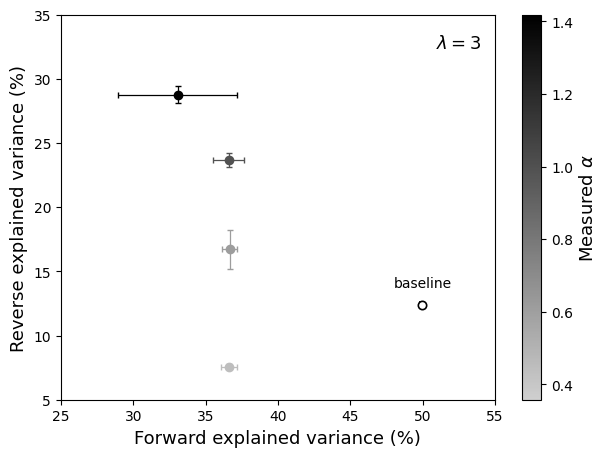

In [43]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

f_ev = [value[0][0] for key, value in dictionary.items()]
f_ev_std = [value[0][1] for key, value in dictionary.items()]
r_ev = [value[0][2] for key, value in dictionary.items()]
r_ev_std = [value[0][3] for key, value in dictionary.items()]
alphas = np.array([value[1][0] for key, value in dictionary.items()])
alphas_std = np.array([value[1][1] for key, value in dictionary.items()])

s_e = [value[2] for key, value in dictionary.items()]
c_f = [value[4][0] for key, value in dictionary.items()]
c_f_std = [value[4][1] for key, value in dictionary.items()]
c_r = [value[4][2] for key, value in dictionary.items()]
c_r_std = [value[4][3] for key, value in dictionary.items()]
u_f = [value[5][0] for key, value in dictionary.items()]
u_f_std = [value[5][1] for key, value in dictionary.items()]
u_r = [value[5][2] for key, value in dictionary.items()]
u_r_std = [value[5][3] for key, value in dictionary.items()]
ns = [value[6] for key, value in dictionary.items()]



# normalize alpha values for colormap
norm = mcolors.Normalize(
    vmin=alphas.min(),
    vmax=alphas.max()
)

cmap = LinearSegmentedColormap.from_list(
    "grayscale_scheme_reversed",
    [
        (0.0, "#cfcfcf"),  # light gray at min
        (0.5, "#666666"),  # medium gray
        (1.0, "#000000"),  # black at max
    ]
)
fig, ax = plt.subplots(figsize=(7, 5))

for f, f_std, r, r_std, a, se, n in zip(
    f_ev,
    f_ev_std,
    r_ev,
    r_ev_std,
    alphas,
    s_e,
    ns
):

    color = cmap(norm(a))
    if se == (0.2,0.4):
        label = rf"$\alpha$ = 0.36 (baseline) | n={n}"
    else:
        label = rf"$\alpha$: [{se[0]}, {se[1]}] | $\lambda=3$ | n={n}"

    if spec_loss_ub == 2 and se == (1.2,1.6):
        break

    if se == (0.2, 0.4):
        ax.errorbar(
            f,
            r,
            xerr=f_std,
            yerr=r_std,
            linestyle="",
            marker="o",
            color="black",
            markerfacecolor="white",
            markeredgecolor="black",
            markeredgewidth=1.2,
            capsize=3,
            label=label
        )
    else:
        ax.errorbar(
            f,
            r,
            xerr=f_std,
            yerr=r_std,
            linestyle="",
            marker="o",
            color=color,
            capsize=2,
            label=label,
            linewidth=0.9
        )

# add colorbar
sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(sm, ax=ax)
cbar.set_label(r"Measured $\alpha$", fontsize=13)

plt.xlabel("Forward explained variance (%)", fontsize=13)
plt.ylabel("Reverse explained variance (%)", fontsize=13)
plt.ylim(5, 35)
plt.xlim(25, 55)
# plt.legend()
# plt.title(r"Forward and Reverse EV by $\alpha$ ($\lambda= 2$ or $3$)", fontsize=15)
# plt.title(r"Forward and Reverse EV by $\alpha$ ($\lambda= 2$)", fontsize=15)

ax.text(
    0.97,
    0.95,
    r"$\lambda = 3$",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=13
)

ax.text(
    0.9,
    0.32,
    r"baseline",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10
)

plt.savefig("rf3.png", dpi=600, bbox_inches="tight")
plt.show()

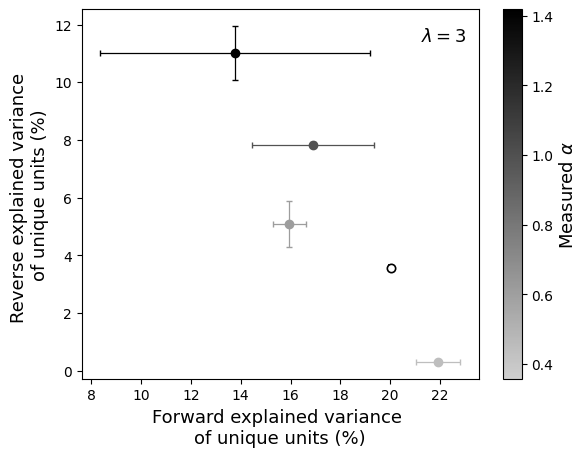

[50.48567442271486, 36.08869711921024, 40.86778408016728, 41.66348086979112, 36.50418400598374]
[0.07414078205784591, 0.017444656560819283, 0.6495465465986676, 0.37317826337502424, 5.656911139896039]
[24.533697637645574, 20.268401611656625, 30.68540590914698, 39.64297846784096, 45.44653299504989]
[0.014235985740235435, 0.01650089435963409, 1.9588067172009787, 2.0343352543191244, 1.2180093520797115]
[20.01933977415824, 21.920904558826752, 15.956527078087632, 16.901452644635874, 13.766254123401245]
[0.07711257954711925, 0.900671859704218, 0.6593897154642763, 2.4522530222197503, 5.424627088864186]
[3.5645901987598467, 0.3186113431981512, 5.080616891038589, 7.840165882547602, 11.01389071657452]
[0.011272683838833064, 0.01945516148431281, 0.805255165415045, 0.07756921807923245, 0.9332375943065188]
[0.35738769 0.44845644 0.61376213 0.99156609 1.41829518]
[7.86846280e-05 1.61026050e-02 1.05885648e-01 2.58366490e-02
 4.57891508e-02]


In [45]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

f_ev = [value[0][0] for key, value in dictionary.items()]
f_ev_std = [value[0][1] for key, value in dictionary.items()]
r_ev = [value[0][2] for key, value in dictionary.items()]
r_ev_std = [value[0][3] for key, value in dictionary.items()]
alphas = np.array([value[1][0] for key, value in dictionary.items()])
alphas_std = np.array([value[1][1] for key, value in dictionary.items()])


s_e = [value[2] for key, value in dictionary.items()]
c_f = [value[4][0] for key, value in dictionary.items()]
c_f_std = [value[4][1] for key, value in dictionary.items()]
c_r = [value[4][2] for key, value in dictionary.items()]
c_r_std = [value[4][3] for key, value in dictionary.items()]
u_f = [value[5][0] for key, value in dictionary.items()]
u_f_std = [value[5][1] for key, value in dictionary.items()]
u_r = [value[5][2] for key, value in dictionary.items()]
u_r_std = [value[5][3] for key, value in dictionary.items()]
ns = [value[6] for key, value in dictionary.items()]



# normalize alpha values for colormap
norm = mcolors.Normalize(
    vmin=alphas.min(),
    vmax=alphas.max()
)

cmap = LinearSegmentedColormap.from_list(
    "grayscale_scheme_reversed",
    [
        (0.0, "#cfcfcf"),  # light gray at min
        (0.5, "#666666"),  # medium gray
        (1.0, "#000000"),  # black at max
    ]
)

fig, ax = plt.subplots()

for uf, uf_std, ur, ur_std, a, se, n in zip(
    u_f,
    u_f_std,
    u_r,
    u_r_std,
    alphas,
    s_e, ns
):

    color = cmap(norm(a))

    if se == (0.2, 0.4):
        ax.errorbar(
            uf,
            ur,
            xerr=uf_std,
            yerr=ur_std,
            linestyle="",
            marker="o",
            color="black",
            markerfacecolor="white",
            markeredgecolor="black",
            markeredgewidth=1.2,
            capsize=3,
            label=rf"$\alpha$ = 0.36 (baseline) | n={n}"
        )
    else:
        ax.errorbar(
            uf,
            ur,
            xerr=uf_std,
            yerr=ur_std,
            linestyle="",
            marker="o",
            color=color,
            capsize=2,
            label=rf"$\alpha$: [{se[0]}, {se[1]}] | n={n}",
            linewidth=0.9
        )
    


# add colorbar
sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(sm, ax=ax)
cbar.set_label(r"Measured $\alpha$", fontsize=13)

plt.xlabel("Forward explained variance \nof unique units (%)", fontsize=13)
plt.ylabel("Reverse explained variance \nof unique units (%)", fontsize=13)
# plt.ylim(5, 35)
# plt.xlim(25, 55)
# plt.legend(fontsize=13)
# plt.title(r"Forward and Reverse EV of Unique Units by $\alpha$ ($\lambda= 3$)", fontsize=15)

ax.text(
    0.97,
    0.95,
    r"$\lambda = 3$",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=13
)

plt.savefig("rfu3.png", dpi=600, bbox_inches="tight")
plt.show()
print(c_f)
print(c_f_std)

print(c_r)
print(c_r_std)

print(u_f)
print(u_f_std)

print(u_r)
print(u_r_std)

print(alphas)
print(alphas_std)

alpha: 0.36 +/- 0.00 | f_ev: 49.97 +/- 0.13 | r_ev: 12.37 +/- 0.02 | n: 5
alpha: 0.45 +/- 0.02 | f_ev: 36.62 +/- 0.56 | r_ev: 7.59 +/- 0.17 | n: 3
alpha: 0.61 +/- 0.11 | f_ev: 36.66 +/- 0.54 | r_ev: 16.72 +/- 1.52 | n: 6
alpha: 0.99 +/- 0.03 | f_ev: 36.61 +/- 1.07 | r_ev: 23.68 +/- 0.52 | n: 13
alpha: 1.42 +/- 0.05 | f_ev: 33.07 +/- 4.14 | r_ev: 28.77 +/- 0.64 | n: 9
alpha: 0.36 +/- 0.00 | f_ev_c: 50.49 +/- 0.07 | f_ev_u: 20.02 +/- 0.08 | r_ev_c: 24.53 +/- 0.01 | r_ev_u: 3.56 +/- 0.01
alpha: 0.45 +/- 0.02 | f_ev_c: 36.09 +/- 0.02 | f_ev_u: 21.92 +/- 0.90 | r_ev_c: 20.27 +/- 0.02 | r_ev_u: 0.32 +/- 0.02
alpha: 0.61 +/- 0.11 | f_ev_c: 40.87 +/- 0.65 | f_ev_u: 15.96 +/- 0.66 | r_ev_c: 30.69 +/- 1.96 | r_ev_u: 5.08 +/- 0.81
alpha: 0.99 +/- 0.03 | f_ev_c: 41.66 +/- 0.37 | f_ev_u: 16.90 +/- 2.45 | r_ev_c: 39.64 +/- 2.03 | r_ev_u: 7.84 +/- 0.08
alpha: 1.42 +/- 0.05 | f_ev_c: 36.50 +/- 5.66 | f_ev_u: 13.77 +/- 5.42 | r_ev_c: 45.45 +/- 1.22 | r_ev_u: 11.01 +/- 0.93


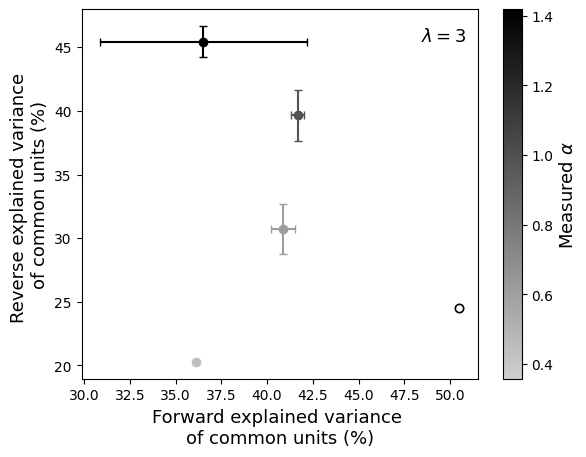

In [47]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

f_ev = [value[0][0] for key, value in dictionary.items()]
f_ev_std = [value[0][1] for key, value in dictionary.items()]
r_ev = [value[0][2] for key, value in dictionary.items()]
r_ev_std = [value[0][3] for key, value in dictionary.items()]
alphas = np.array([value[1][0] for key, value in dictionary.items()])
alphas_std = np.array([value[1][1] for key, value in dictionary.items()])

s_e = [value[2] for key, value in dictionary.items()]
c_f = [value[4][0] for key, value in dictionary.items()]
c_f_std = [value[4][1] for key, value in dictionary.items()]
c_r = [value[4][2] for key, value in dictionary.items()]
c_r_std = [value[4][3] for key, value in dictionary.items()]
u_f = [value[5][0] for key, value in dictionary.items()]
u_f_std = [value[5][1] for key, value in dictionary.items()]
u_r = [value[5][2] for key, value in dictionary.items()]
u_r_std = [value[5][3] for key, value in dictionary.items()]
ns = [value[6] for key, value in dictionary.items()]

for i in range(len(alphas)):
    print(f"alpha: {alphas[i]:.2f} +/- {alphas_std[i]:.2f} | f_ev: {f_ev[i]:.2f} +/- {f_ev_std[i]:.2f} | r_ev: {r_ev[i]:.2f} +/- {r_ev_std[i]:.2f} | n: {ns[i]}")

for i in range(len(alphas)):
    print(f"alpha: {alphas[i]:.2f} +/- {alphas_std[i]:.2f} | f_ev_c: {c_f[i]:.2f} +/- {c_f_std[i]:.2f} | f_ev_u: {u_f[i]:.2f} +/- {u_f_std[i]:.2f} | r_ev_c: {c_r[i]:.2f} +/- {c_r_std[i]:.2f} | r_ev_u: {u_r[i]:.2f} +/- {u_r_std[i]:.2f}")

# normalize alpha values for colormap
norm = mcolors.Normalize(
    vmin=alphas.min(),
    vmax=alphas.max()
)

cmap = LinearSegmentedColormap.from_list(
    "grayscale_scheme_reversed",
    [
        (0.0, "#cfcfcf"),  # light gray at min
        (0.5, "#666666"),  # medium gray
        (1.0, "#000000"),  # black at max
    ]
)

fig, ax = plt.subplots()

for cf, cf_std, cr, cr_std, a, se, n in zip(
    c_f,
    c_f_std,
    c_r,
    c_r_std,
    alphas,
    s_e, ns
):

    color = cmap(norm(a))

    if se == (0.2, 0.4):
        ax.errorbar(
            cf,
            cr,
            xerr=cf_std,
            yerr=cr_std,
            linestyle="",
            marker="o",
            color="black",
            markerfacecolor="white",
            markeredgecolor="black",
            markeredgewidth=1.2,
            capsize=3,
            label=rf"$\alpha$ = 0.36 (baseline) | n={n}"
        )
    else:
        ax.errorbar(
            cf,
            cr,
            xerr=cf_std,
            yerr=cr_std,
            linestyle="",
            marker="o",
            color=color,
            capsize=3,
            label=rf"$\alpha$: [{se[0]}, {se[1]}] | n={n}"
        )

# add colorbar
sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(sm, ax=ax)
cbar.set_label(r"Measured $\alpha$", fontsize=13)

plt.xlabel("Forward explained variance \nof common units (%)", fontsize=13)
plt.ylabel("Reverse explained variance \nof common units (%)", fontsize=13)
# plt.ylim(5, 35)
# plt.xlim(25, 55)
# plt.legend()
# plt.title(r"Forward and Reverse EV of Common Units by $\alpha$ ($\lambda= 3$)", fontsize=15)

ax.text(
    0.97,
    0.95,
    r"$\lambda = 3$",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=13
)

plt.savefig("rfc3.png", dpi=600, bbox_inches="tight")
plt.show()

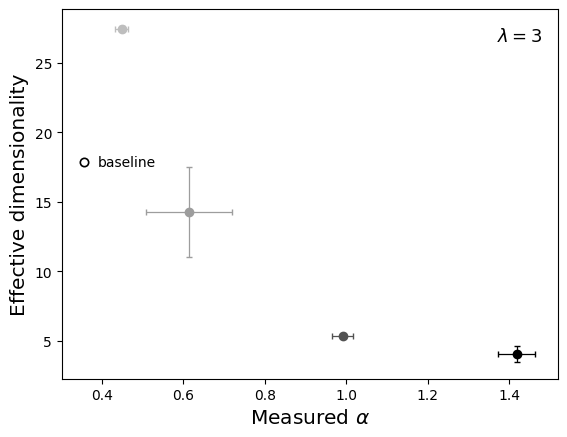

In [50]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

f_ev = [value[0][0] for key, value in dictionary.items()]
f_ev_std = [value[0][1] for key, value in dictionary.items()]
r_ev = [value[0][2] for key, value in dictionary.items()]
r_ev_std = [value[0][3] for key, value in dictionary.items()]
alphas = np.array([value[1][0] for key, value in dictionary.items()])
alphas_std = np.array([value[1][1] for key, value in dictionary.items()])
s_e = [value[2] for key, value in dictionary.items()]
eds = [value[3][0] for key, value in dictionary.items()]
ed_stds = [value[3][1] for key, value in dictionary.items()]
ns = [value[6] for key, value in dictionary.items()]


# normalize alpha values for colormap
norm = mcolors.Normalize(
    vmin=alphas.min(),
    vmax=alphas.max()
)

cmap = LinearSegmentedColormap.from_list(
    "grayscale_scheme_reversed",
    [
        (0.0, "#cfcfcf"),  # light gray at min
        (0.5, "#666666"),  # medium gray
        (1.0, "#000000"),  # black at max
    ]
)

fig, ax = plt.subplots()

for ed, ed_std, f, f_std, r, r_std, a, a_std, se, n in zip(
    eds, ed_stds, f_ev,
    f_ev_std,
    r_ev,
    r_ev_std,
    alphas, alphas_std,
    s_e, ns
):

    color = cmap(norm(a))

    if se == (0.2, 0.4):
        ax.errorbar(
            a,
            ed,
            xerr=a_std,
            yerr=ed_std,
            linestyle="",
            marker="o",
            color="black",
            markerfacecolor="white",
            markeredgecolor="black",
            markeredgewidth=1.2,
            capsize=3,
            label=rf"$\alpha$ = 0.36 (baseline) | n={n}"
        )
    else:
        ax.errorbar(
            a,
            ed,
            xerr=a_std,
            yerr=ed_std,
            linestyle="",
            marker="o",
            linewidth=0.9,
            color=color,
            capsize=2,
            label=rf"$\alpha$: [{se[0]}, {se[1]}] | n={n}"
        )

# add colorbar
sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

# cbar = plt.colorbar(sm, ax=ax)
# cbar.set_label(r"Measured $\alpha$", fontsize=15)

plt.ylabel("Effective dimensionality", fontsize=14.5)
plt.xlabel(r"Measured $\alpha$", fontsize=14.5)
# plt.ylim(5, 35)
# plt.xlim(25, 55)
# plt.legend()
# plt.title(r"Effective Dimensionality vs $\alpha$ ($\lambda= 2$ or $3$)", fontsize=15)
# plt.title(r"Effective Dimensionality vs $\alpha$ ($\lambda= 3$)", fontsize=15)

ax.text(
    0.97,
    0.95,
    r"$\lambda = 3$",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=13
)
ax.text(
    0.19,
    0.605,
    r"baseline",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10
)

plt.savefig("edalpha3.png", dpi=600, bbox_inches="tight")
plt.show()

19.82654640557975 +/- 0.031527386069624734
12.567229436435099 +/- 0.22991646665216475
22.969034923315558 +/- 1.432961487940276
28.758199005951575 +/- 0.5043804769926907
30.768376074908304 +/- 1.830083142037645


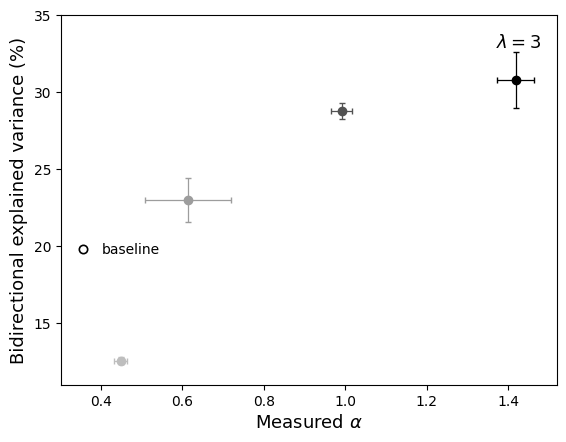

In [53]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

f_ev = np.array([value[0][0] for key, value in dictionary.items()])
f_ev_std = np.array([value[0][1] for key, value in dictionary.items()])
r_ev = np.array([value[0][2] for key, value in dictionary.items()])
r_ev_std = np.array([value[0][3] for key, value in dictionary.items()])
alphas = np.array([value[1][0] for key, value in dictionary.items()])
alphas_std = np.array([value[1][1] for key, value in dictionary.items()])
s_e = [value[2] for key, value in dictionary.items()]
bpi = (2*f_ev*r_ev)/(f_ev+r_ev)
ns = [value[6] for key, value in dictionary.items()]


sigma_bpi = np.sqrt(
    (
        (2 * r_ev**2 / (f_ev + r_ev)**2) * f_ev_std
    )**2
    +
    (
        (2 * f_ev**2 / (f_ev + r_ev)**2) * r_ev_std
    )**2
)

# normalize alpha values for colormap
norm = mcolors.Normalize(
    vmin=alphas.min(),
    vmax=alphas.max()
)

cmap = LinearSegmentedColormap.from_list(
    "grayscale_scheme_reversed",
    [
        (0.0, "#cfcfcf"),  # light gray at min
        (0.5, "#666666"),  # medium gray
        (1.0, "#000000"),  # black at max
    ]
)

fig, ax = plt.subplots()

for b, b_std, f, f_std, r, r_std, a, a_std, se, n in zip(
    bpi, sigma_bpi, f_ev,
    f_ev_std,
    r_ev,
    r_ev_std,
    alphas, alphas_std,
    s_e, ns
):
    print(f"{b} +/- {b_std}")

    color = cmap(norm(a))

    if se == (0.2, 0.4):
        ax.errorbar(
            a,
            b,
            xerr=a_std,
            yerr=b_std,
            linestyle="",
            marker="o",
            color="black",
            markerfacecolor="white",
            markeredgecolor="black",
            markeredgewidth=1.2,
            capsize=3,
            label=rf"$\alpha$ = 0.36 (baseline) | n={n}"
        )
    else:
        ax.errorbar(
            a,
            b,
            xerr=a_std,
            yerr = b_std,
            linestyle="",
            marker="o",
            color=color,
            capsize=2,
            linewidth=0.9,
            label = rf"$\alpha$: [{se[0]}, {se[1]}] | n={n}"
        )

# add colorbar
sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

# cbar = plt.colorbar(sm, ax=ax)
# cbar.set_label(r"Measured $\alpha$", fontsize=15)

plt.ylabel("Bidirectional explained variance (%)", fontsize=13)
plt.xlabel(r"Measured $\alpha$", fontsize=13)
plt.ylim(11, 35)
# plt.xlim(25, 55)
# plt.legend()
# plt.title(r"Bidirectional Explained Variance versus $\alpha$ ($\lambda= 3$)", fontsize=15)

ax.text(
    0.97,
    0.95,
    r"$\lambda = 3$",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=13
)

ax.text(
    0.2,
    0.384,
    r"baseline",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10
)

plt.savefig("balpha3.png", dpi=600, bbox_inches="tight")
plt.show()

s: 0.2 | e: 0.4
s: 0.2 | e: 0.5
s: 0.5 | e: 0.8
s: 0.8 | e: 1.2
s: 1.2 | e: 1.6


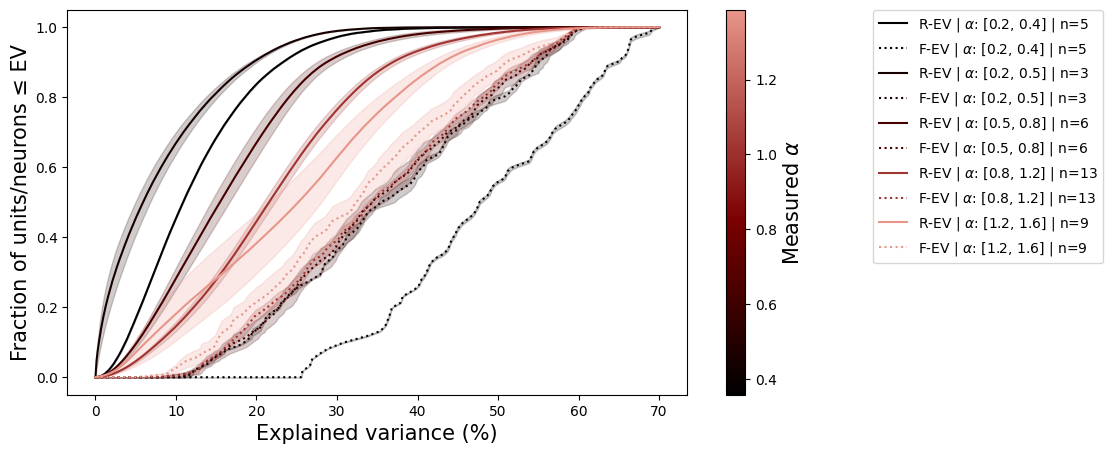

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

# -------------------------------------------------
# colormap setup (same as your scatter/errorbar plot)
# -------------------------------------------------

alpha_means_for_color = []

for (s, e) in alpha_ranges:

    if s == 0.2 and e==0.4:
        df_tmp = df[
            ((df["spectral_loss_coeff"] == 0) &
             (df["tau"] == 0.2))
        ]
    else:
        df_tmp = df[
            (df["version"] == "fixed alpha_loss_04042026")
            & (df["epochs"] >= 199)
            & (df["spectral_loss_coeff"] >= spec_loss_lb)
            & ((df["recomputed_alpha"] >= s) &
               (df["recomputed_alpha"] <= e))
            # & (df["recomputed_R_EV"] <= 35)
            # & (df["recomputed_R_EV"] > 10)
        ]

    alpha_means_for_color.append(
        df_tmp["recomputed_alpha"].mean()
    )

alpha_means_for_color = np.array(alpha_means_for_color)



s: 0.2 | e: 0.4
s: 0.2 | e: 0.5
s: 0.5 | e: 0.8
s: 0.8 | e: 1.2
s: 1.2 | e: 1.6


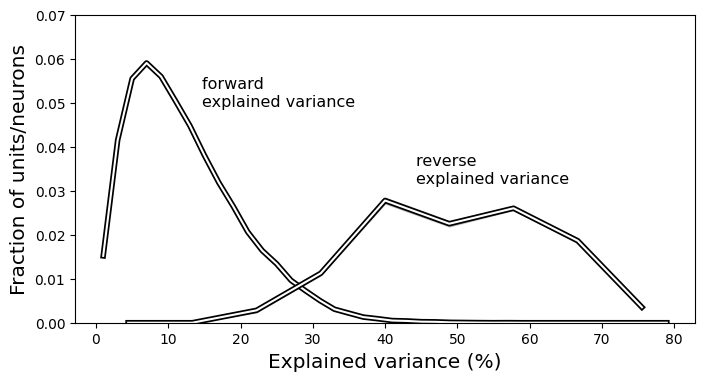

In [77]:
hist_stuff = []
max_ev = 80

r_bins = np.linspace(0, max_ev, 41)
f_bins = np.linspace(0, max_ev, 10)

r_bin_centers = 0.5 * (r_bins[:-1] + r_bins[1:])
f_bin_centers = 0.5 * (f_bins[:-1] + f_bins[1:])

for (s, e), alpha_color_mean in zip(alpha_ranges, alpha_means_for_color):

    print(f"s: {s} | e: {e}")

    if s == 0.2 and e==0.4:
        df_filtered = df[
            ((df["spectral_loss_coeff"] == 0) &
             (df["tau"] == 0.2))
        ]
    else:
        # df_filtered = df[
        #     (df["version"] == "fixed alpha_loss_04042026")
        #     & (df["epochs"] >= 199)
        #     & (df["spectral_loss_coeff"] >= spec_loss_lb)
        #     & ((df["recomputed_alpha"] >= s) &
        #        (df["recomputed_alpha"] <= e))
        #     & (df["recomputed_R_EV"] <= 35)
        #     & (df["recomputed_R_EV"] > 10)
        # ]
        # df_filtered = df[(df["version"]=="fixed alpha_loss_04042026") & (df["epochs"]>=199) & (df["spectral_loss_coeff"]>=spec_loss_lb)&((df["recomputed_alpha"]>=s) & (df["recomputed_alpha"]<=e)) & (df["recomputed_R_EV"]<=35) & (df["recomputed_R_EV"]>10) & ((df["recomputed_R_EV"]>20)|(df["recomputed_alpha"]<1.3))]
        df_filtered = df[(df["version"]=="fixed alpha_loss_04042026") & (df["epochs"]>=199) & (df["spectral_loss_coeff"]>=spec_loss_lb)&((df["recomputed_alpha"]>=s) & (df["recomputed_alpha"]<=e))]


    f_evs = []
    r_evs = []
    alphas = []

    for idx, row in df_filtered.iterrows():

        ckpt_path = row["ckpt_path"]

        try:
            r_ev, f_ev = fetch_ev_arrs_from_ckpt_path(ckpt_path)

            measured_alpha = row["recomputed_alpha"]
            alphas.append(measured_alpha)

            r_ev = np.asarray(r_ev)
            f_ev = np.asarray(f_ev)

            r_ev = r_ev[(r_ev >= 0) & (r_ev <= max_ev)]
            f_ev = f_ev[(f_ev >= 0) & (f_ev <= max_ev)]

            r_evs.append(r_ev)
            f_evs.append(f_ev)

        except Exception as e:
            print(e)

    # ---------------- R-EV histogram density ----------------

    all_hist_r = []

    for r_ev in r_evs:
        hist_r, _ = np.histogram(
            r_ev,
            bins=r_bins,
            density=True
        )

        all_hist_r.append(hist_r)

    all_hist_r = np.array(all_hist_r)

    mean_hist_r = all_hist_r.mean(axis=0)

    sem_hist_r = (
        all_hist_r.std(axis=0, ddof=1)
        / np.sqrt(all_hist_r.shape[0])
    )

    # ---------------- F-EV histogram density ----------------

    all_hist_f = []

    for f_ev in f_evs:
        hist_f, _ = np.histogram(
            f_ev,
            bins=f_bins,
            density=True
        )

        all_hist_f.append(hist_f)

    all_hist_f = np.array(all_hist_f)

    mean_hist_f = all_hist_f.mean(axis=0)

    sem_hist_f = (
        all_hist_f.std(axis=0, ddof=1)
        / np.sqrt(all_hist_f.shape[0])
    )

    color = cmap(norm(np.mean(alphas)))

    hist_stuff.append({
        "r": (r_bin_centers, mean_hist_r, sem_hist_r),
        "f": (f_bin_centers, mean_hist_f, sem_hist_f),
        "other": [alphas, s, e, color]
    })

# -------------------------------------------------
# plotting
# -------------------------------------------------


# norm = mcolors.Normalize(
#     vmin=alpha_means_for_color.min(),
#     vmax=alpha_means_for_color.max()
# )

# cmap = LinearSegmentedColormap.from_list(
#     "grayscale_scheme_reversed",
#     [
#         (0.0, "#cfcfcf"),  # light gray at min
#         (0.5, "#666666"),  # medium gray
#         (1.0, "#000000"),  # black at max
#     ]
# )

fig, ax = plt.subplots(figsize=(8, 4))

for hist in hist_stuff:

    r_bin_centers, mean_hist_r, sem_hist_r = hist["r"]
    f_bin_centers, mean_hist_f, sem_hist_f = hist["f"]

    alphas = hist["other"][0]
    s = hist["other"][1]
    e = hist["other"][2]
    color = hist["other"][3]

    if e >0.4:
        break
        
    # ax.plot(
    #     r_bin_centers,
    #     mean_hist_r,
    #     label=rf"R-EV | $\alpha$: [{s}, {e}] | n={len(alphas)}",
    #     color=color
    # )

    # ax.fill_between(
    #     r_bin_centers,
    #     mean_hist_r - sem_hist_r,
    #     mean_hist_r + sem_hist_r,
    #     alpha=0.2,
    #     color=color
    # )

    # ax.plot(
    #     f_bin_centers,
    #     mean_hist_f,
    #     label=rf"F-EV | $\alpha$: [{s}, {e}] | n={len(alphas)}",
    #     color=color,
    #     ls=":"
    # )

    # ax.fill_between(
    #     f_bin_centers,
    #     mean_hist_f - sem_hist_f,
    #     mean_hist_f + sem_hist_f,
    #     alpha=0.2,
    #     color=color
    # )

    ax.plot(
        r_bin_centers,
        mean_hist_r,
        label=rf"R-EV | $\alpha$: [{s}, {e}] | n={len(alphas)}",
        color="white",
        # path_effects=[pe.Stroke(linewidth=2.5, foreground="black"), pe.Normal()]
        path_effects=[pe.Stroke(linewidth=4, foreground="black"), pe.Normal()]

    )

    ax.fill_between(
        r_bin_centers,
        mean_hist_r - sem_hist_r,
        mean_hist_r + sem_hist_r,
        alpha=0.2,
        color="black"
    )

    ax.plot(
        f_bin_centers,
        mean_hist_f,
        label=rf"F-EV | $\alpha$: [{s}, {e}] | n={len(alphas)}",
        color="white",
        # path_effects=[pe.Stroke(linewidth=2.5, foreground="black"), pe.Normal()]
        path_effects=[pe.Stroke(linewidth=4, foreground="black"), pe.Normal()]

    )

    ax.fill_between(
        f_bin_centers,
        mean_hist_f - sem_hist_f,
        mean_hist_f + sem_hist_f,
        alpha=0.2,
        color="black"
    )

ax.set_xlabel("Explained variance (%)", fontsize=14.5)
ax.set_ylabel("Fraction of units/neurons", fontsize=14.5)

# ax.set_title(
#     "Histogram density of unit-wise forward & reverse \n"
#     + rf"explained variance across $\alpha$ ($\lambda= 3$)",
#     fontsize=14
# )

sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

# cbar = plt.colorbar(sm, ax=ax)

# cbar.set_label(
#     r"Measured $\alpha$",
#     fontsize=15
# )

# ax.legend(
#     bbox_to_anchor=(1.2, 1),
#     loc="upper left",
#     borderaxespad=0
# )

ax.text(
    0.205,
    0.8,
    "forward \nexplained variance",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=11.5
)
ax.text(
    0.55,
    0.55,
    "reverse \nexplained variance",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=11.5
)
plt.ylim(0, 0.07)

plt.savefig("histbaseline3.png", dpi=600, bbox_inches="tight")
plt.show()


s: 0.2 | e: 0.4
s: 0.2 | e: 0.5
s: 0.5 | e: 0.8
s: 0.8 | e: 1.2
s: 1.2 | e: 1.6


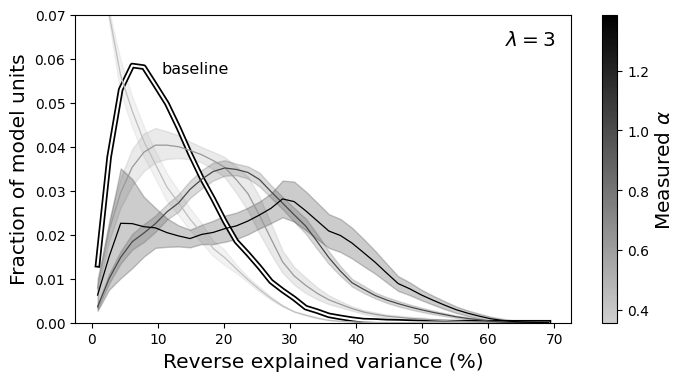

In [44]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import numpy as np

hist_stuff = []
max_ev = 70

r_bins = np.linspace(0, max_ev, 41)
f_bins = np.linspace(0, max_ev, 10)

r_bin_centers = 0.5 * (r_bins[:-1] + r_bins[1:])
f_bin_centers = 0.5 * (f_bins[:-1] + f_bins[1:])

for (s, e), alpha_color_mean in zip(alpha_ranges, alpha_means_for_color):

    print(f"s: {s} | e: {e}")

    if s == 0.2 and e==0.4:
        df_filtered = df[
            ((df["spectral_loss_coeff"] == 0) &
             (df["tau"] == 0.2))
        ]
    else:
        # df_filtered = df[
        #     (df["version"] == "fixed alpha_loss_04042026")
        #     & (df["epochs"] >= 199)
        #     & (df["spectral_loss_coeff"] >= spec_loss_lb)
        #     & ((df["recomputed_alpha"] >= s) &
        #        (df["recomputed_alpha"] <= e))
        #     & (df["recomputed_R_EV"] <= 35)
        #     & (df["recomputed_R_EV"] > 10)
        # ]
        # df_filtered = df[(df["version"]=="fixed alpha_loss_04042026") & (df["epochs"]>=199) & (df["spectral_loss_coeff"]>=spec_loss_lb)&((df["recomputed_alpha"]>=s) & (df["recomputed_alpha"]<=e)) & (df["recomputed_R_EV"]<=35) & (df["recomputed_R_EV"]>10) & ((df["recomputed_R_EV"]>20)|(df["recomputed_alpha"]<1.3))]
        df_filtered = df[(df["version"]=="fixed alpha_loss_04042026") & (df["epochs"]>=199) & (df["spectral_loss_coeff"]>=spec_loss_lb)&((df["recomputed_alpha"]>=s) & (df["recomputed_alpha"]<=e))]


    f_evs = []
    r_evs = []
    alphas = []

    for idx, row in df_filtered.iterrows():

        ckpt_path = row["ckpt_path"]

        try:
            r_ev, f_ev = fetch_ev_arrs_from_ckpt_path(ckpt_path)

            measured_alpha = row["recomputed_alpha"]
            alphas.append(measured_alpha)

            r_ev = np.asarray(r_ev)
            f_ev = np.asarray(f_ev)

            r_ev = r_ev[(r_ev >= 0) & (r_ev <= max_ev)]
            f_ev = f_ev[(f_ev >= 0) & (f_ev <= max_ev)]

            r_evs.append(r_ev)
            f_evs.append(f_ev)

        except Exception as e:
            print(e)

    # ---------------- R-EV histogram density ----------------

    all_hist_r = []

    for r_ev in r_evs:
        hist_r, _ = np.histogram(
            r_ev,
            bins=r_bins,
            density=True
        )

        all_hist_r.append(hist_r)

    all_hist_r = np.array(all_hist_r)

    mean_hist_r = all_hist_r.mean(axis=0)

    sem_hist_r = (
        all_hist_r.std(axis=0, ddof=1)
        / np.sqrt(all_hist_r.shape[0])
    )

    # ---------------- F-EV histogram density ----------------

    all_hist_f = []

    for f_ev in f_evs:
        hist_f, _ = np.histogram(
            f_ev,
            bins=f_bins,
            density=True
        )

        all_hist_f.append(hist_f)

    all_hist_f = np.array(all_hist_f)

    mean_hist_f = all_hist_f.mean(axis=0)

    sem_hist_f = (
        all_hist_f.std(axis=0, ddof=1)
        / np.sqrt(all_hist_f.shape[0])
    )

    color = cmap(norm(np.mean(alphas)))

    hist_stuff.append({
        "r": (r_bin_centers, mean_hist_r, sem_hist_r),
        "f": (f_bin_centers, mean_hist_f, sem_hist_f),
        "other": [alphas, s, e, color]
    })

# -------------------------------------------------
# plotting
# -------------------------------------------------

norm = mcolors.Normalize(
    vmin=alpha_means_for_color.min(),
    vmax=alpha_means_for_color.max()
)

cmap = LinearSegmentedColormap.from_list(
    "grayscale_scheme_reversed",
    [
        (0.0, "#cfcfcf"),  # light gray at min
        (0.5, "#666666"),  # medium gray
        (1.0, "#000000"),  # black at max
    ]
)

fig, ax = plt.subplots(figsize=(8, 4))

for hist in hist_stuff:

    r_bin_centers, mean_hist_r, sem_hist_r = hist["r"]
    f_bin_centers, mean_hist_f, sem_hist_f = hist["f"]

    alphas = hist["other"][0]
    s = hist["other"][1]
    e = hist["other"][2]
    color = cmap(norm(np.mean(alphas)))

    if s == 0.2 and e==0.4:
        line, = ax.plot(
            r_bin_centers,
            mean_hist_r,
            label=rf"R-EV | $\alpha$: [{s}, {e}] | n={len(alphas)}",
            color="white",
            # path_effects=[pe.Stroke(linewidth=2.5, foreground="black"), pe.Normal()]
            path_effects=[pe.Stroke(linewidth=4, foreground="black"), pe.Normal()]

        )

        ax.fill_between(
            r_bin_centers,
            mean_hist_r - sem_hist_r,
            mean_hist_r + sem_hist_r,
            alpha=0.2,
            color="black"
        )
    else:
        ax.plot(
            r_bin_centers,
            mean_hist_r,
            label=rf"R-EV | $\alpha$: [{s}, {e}] | n={len(alphas)}",
            color=color,
            linewidth=0.9
        )

        ax.fill_between(
            r_bin_centers,
            mean_hist_r - sem_hist_r,
            mean_hist_r + sem_hist_r,
            alpha=0.2,
            color=color
        )

    # ax.plot(
    #     f_bin_centers,
    #     mean_hist_f,
    #     label=rf"F-EV | $\alpha$: [{s}, {e}] | n={len(alphas)}",
    #     color=color,
    #     ls=":"
    # )

    # ax.fill_between(
    #     f_bin_centers,
    #     mean_hist_f - sem_hist_f,
    #     mean_hist_f + sem_hist_f,
    #     alpha=0.2,
    #     color=color
    # )

ax.set_xlabel("Reverse explained variance (%)", fontsize=14.5)
ax.set_ylabel("Fraction of model units", fontsize=14.5)

# ax.set_title(
#     "Histogram density of unit-wise reverse \n"
#     + rf"explained variance across $\alpha$ ($\lambda= 3$)",
#     fontsize=14
# )

sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(sm, ax=ax)

cbar.set_label(
    r"Measured $\alpha$",
    fontsize=14.5
)

# ax.legend(
#     bbox_to_anchor=(1.2, 1),
#     loc="upper left",
#     borderaxespad=0
# )

ax.text(
    0.97,
    0.95,
    r"$\lambda = 3$",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=14.5
)

ax.text(
    0.31,
    0.85,
    r"baseline",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=11.5
)

plt.ylim(0, 0.07)
plt.savefig("rhist3.png", dpi=600, bbox_inches="tight")
plt.show()

s: 0.2 | e: 0.4
s: 0.2 | e: 0.5
s: 0.5 | e: 0.8
s: 0.8 | e: 1.2
s: 1.2 | e: 1.6


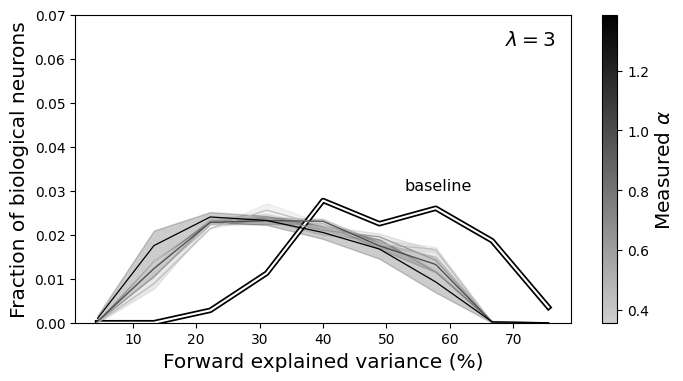

In [46]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import numpy as np

norm = mcolors.Normalize(
    vmin=alpha_means_for_color.min(),
    vmax=alpha_means_for_color.max()
)

cmap = LinearSegmentedColormap.from_list(
    "grayscale_scheme_reversed",
    [
        (0.0, "#cfcfcf"),  # light gray at min
        (0.5, "#666666"),  # medium gray
        (1.0, "#000000"),  # black at max
    ]
)

hist_stuff = []
max_ev = 80

r_bins = np.linspace(0, max_ev, 41)
f_bins = np.linspace(0, max_ev, 10)

r_bin_centers = 0.5 * (r_bins[:-1] + r_bins[1:])
f_bin_centers = 0.5 * (f_bins[:-1] + f_bins[1:])

for (s, e), alpha_color_mean in zip(alpha_ranges, alpha_means_for_color):

    print(f"s: {s} | e: {e}")

    if s == 0.2 and e==0.4:
        df_filtered = df[
            ((df["spectral_loss_coeff"] == 0) &
             (df["tau"] == 0.2))
        ]
    else:
        # df_filtered = df[
        #     (df["version"] == "fixed alpha_loss_04042026")
        #     & (df["epochs"] >= 199)
        #     & (df["spectral_loss_coeff"] >= spec_loss_lb)
        #     & ((df["recomputed_alpha"] >= s) &
        #        (df["recomputed_alpha"] <= e))
        #     & (df["recomputed_R_EV"] <= 35)
        #     & (df["recomputed_R_EV"] > 10)
        # ]
        # df_filtered = df[(df["version"]=="fixed alpha_loss_04042026") & (df["epochs"]>=199) & (df["spectral_loss_coeff"]>=spec_loss_lb)&((df["recomputed_alpha"]>=s) & (df["recomputed_alpha"]<=e)) & (df["recomputed_R_EV"]<=35) & (df["recomputed_R_EV"]>10) & ((df["recomputed_R_EV"]>20)|(df["recomputed_alpha"]<1.3))]
        df_filtered = df[(df["version"]=="fixed alpha_loss_04042026") & (df["epochs"]>=199) & (df["spectral_loss_coeff"]>=spec_loss_lb)&((df["recomputed_alpha"]>=s) & (df["recomputed_alpha"]<=e))]


    f_evs = []
    r_evs = []
    alphas = []

    for idx, row in df_filtered.iterrows():

        ckpt_path = row["ckpt_path"]

        try:
            r_ev, f_ev = fetch_ev_arrs_from_ckpt_path(ckpt_path)

            measured_alpha = row["recomputed_alpha"]
            alphas.append(measured_alpha)

            r_ev = np.asarray(r_ev)
            f_ev = np.asarray(f_ev)

            r_ev = r_ev[(r_ev >= 0) & (r_ev <= max_ev)]
            f_ev = f_ev[(f_ev >= 0) & (f_ev <= max_ev)]

            r_evs.append(r_ev)
            f_evs.append(f_ev)

        except Exception as e:
            print(e)

    # ---------------- R-EV histogram density ----------------

    all_hist_r = []

    for r_ev in r_evs:
        hist_r, _ = np.histogram(
            r_ev,
            bins=r_bins,
            density=True
        )

        all_hist_r.append(hist_r)

    all_hist_r = np.array(all_hist_r)

    mean_hist_r = all_hist_r.mean(axis=0)

    sem_hist_r = (
        all_hist_r.std(axis=0, ddof=1)
        / np.sqrt(all_hist_r.shape[0])
    )

    # ---------------- F-EV histogram density ----------------

    all_hist_f = []

    for f_ev in f_evs:
        hist_f, _ = np.histogram(
            f_ev,
            bins=f_bins,
            density=True
        )

        all_hist_f.append(hist_f)

    all_hist_f = np.array(all_hist_f)

    mean_hist_f = all_hist_f.mean(axis=0)

    sem_hist_f = (
        all_hist_f.std(axis=0, ddof=1)
        / np.sqrt(all_hist_f.shape[0])
    )

    color = cmap(norm(np.mean(alphas)))

    hist_stuff.append({
        "r": (r_bin_centers, mean_hist_r, sem_hist_r),
        "f": (f_bin_centers, mean_hist_f, sem_hist_f),
        "other": [alphas, s, e, color]
    })

# -------------------------------------------------
# plotting
# -------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 4))

for hist in hist_stuff:

    r_bin_centers, mean_hist_r, sem_hist_r = hist["r"]
    f_bin_centers, mean_hist_f, sem_hist_f = hist["f"]

    alphas = hist["other"][0]
    s = hist["other"][1]
    e = hist["other"][2]
    color = hist["other"][3]

    # ax.plot(
    #     r_bin_centers,
    #     mean_hist_r,
    #     label=rf"R-EV | $\alpha$: [{s}, {e}] | n={len(alphas)}",
    #     color=color
    # )

    # ax.fill_between(
    #     r_bin_centers,
    #     mean_hist_r - sem_hist_r,
    #     mean_hist_r + sem_hist_r,
    #     alpha=0.2,
    #     color=color
    # )

    if s == 0.2 and e==0.4:
        ax.plot(
            f_bin_centers,
            mean_hist_f,
            label=rf"F-EV | $\alpha$: [{s}, {e}] | n={len(alphas)}",
            color="white",
            path_effects=[pe.Stroke(linewidth=4, foreground="black"), pe.Normal()],
            # ls=":"
        )

        ax.fill_between(
            f_bin_centers,
            mean_hist_f - sem_hist_f,
            mean_hist_f + sem_hist_f,
            alpha=0.2,
            color="white"
        )
    else:
        ax.plot(
            f_bin_centers,
            mean_hist_f,
            label=rf"F-EV | $\alpha$: [{s}, {e}] | n={len(alphas)}",
            color=color,
            linewidth=0.9
            # ls=":"
        )

        ax.fill_between(
            f_bin_centers,
            mean_hist_f - sem_hist_f,
            mean_hist_f + sem_hist_f,
            alpha=0.2,
            color=color
        )

ax.set_xlabel("Forward explained variance (%)", fontsize=14.5)
ax.set_ylabel("Fraction of biological neurons", fontsize=14.5)

# ax.set_title(
#     "Histogram density of unit-wise reverse \n"
#     + rf"explained variance across $\alpha$ ($\lambda= 3$)",
#     fontsize=14
# )

sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(sm, ax=ax)

cbar.set_label(
    r"Measured $\alpha$",
    fontsize=14.5
)

# ax.legend(
#     bbox_to_anchor=(1.2, 1),
#     loc="upper left",
#     borderaxespad=0
# )

ax.text(
    0.97,
    0.95,
    r"$\lambda = 3$",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=14.5
)

ax.text(
    0.8,
    0.47,
    r"baseline",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=11.5
)

plt.ylim(0, 0.07)
# plt.savefig("f3_gaussians.png", dpi=600, bbox_inches="tight")
plt.savefig("fhist3.png", dpi=600, bbox_inches="tight")
plt.show()